In [1]:
data_dir="/kaggle/input/datasets/freshwater-fish-dataset/Freshwater Fish Disease Aquaculture in south asia"

In [4]:
from torchvision import datasets
from torch.utils.data import random_split
import torch

full_dataset = datasets.ImageFolder(
    data_dir,
    transform=train_tf
)

class_names = full_dataset.classes

print("Classes:", class_names)

print("Total Images:", len(full_dataset))

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train Size:", len(train_dataset))
print("Validation Size:", len(val_dataset))

Classes: ['Test', 'Train']
Total Images: 2450
Train Size: 1960
Validation Size: 490


In [3]:
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 16

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

val_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

In [7]:
full_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "Train"),
    transform=train_tf
)

class_names = full_dataset.classes

print(class_names)

['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']


In [6]:
from torchvision import datasets
from torch.utils.data import random_split
import torch
import os

full_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "Train"),
    transform=train_tf
)

class_names = full_dataset.classes

print("Classes:", class_names)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

test_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "Test"),
    transform=val_tf
)

print("Train Size:", len(train_dataset))
print("Validation Size:", len(val_dataset))
print("Test Size:", len(test_dataset))

Classes: ['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']
Train Size: 1400
Validation Size: 350
Test Size: 700


In [9]:
from torch.utils.data import DataLoader

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models

from torch.utils.data import (
    DataLoader,
    random_split
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

In [12]:
print(class_names)

['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']


In [13]:
print(len(train_loader))

88


In [14]:
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Train batches: 88
Val batches: 22
Test batches: 44
Classes: ['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']
Number of classes: 7


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [16]:
from torchvision import models
import torch.nn as nn

model = models.efficientnet_b0(
    weights="DEFAULT"
)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    len(class_names)
)

model = model.to(device)

print("EfficientNet-B0 Loaded Successfully")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 147MB/s]


EfficientNet-B0 Loaded Successfully


In [17]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-5,
    weight_decay=1e-4
)

In [18]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)

In [19]:
EPOCHS = 30

best_acc = 0

train_losses = []
val_losses = []

train_accs = []
val_accs = []

In [20]:
print(next(model.parameters()).device)

cuda:0


In [21]:
for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    # ======================
    # TRAINING
    # ======================

    model.train()

    train_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

    train_loss_epoch = train_loss / len(train_loader)
    train_acc_epoch = correct / total

    train_losses.append(train_loss_epoch)
    train_accs.append(train_acc_epoch)

    print(
        f"Train Loss: {train_loss_epoch:.4f}, "
        f"Train Acc: {train_acc_epoch:.4f}"
    )

    # ======================
    # VALIDATION
    # ======================

    model.eval()

    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            total += labels.size(0)

    val_loss_epoch = val_loss / len(val_loader)
    val_acc_epoch = correct / total

    val_losses.append(val_loss_epoch)
    val_accs.append(val_acc_epoch)

    print(
        f"Val Loss: {val_loss_epoch:.4f}, "
        f"Val Acc: {val_acc_epoch:.4f}"
    )

    scheduler.step(val_acc_epoch)

    if val_acc_epoch > best_acc:

        best_acc = val_acc_epoch

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_efficientnet_b0.pth"
        )

        print("✅ Best Model Saved")


Epoch 1/30
Train Loss: 1.8668, Train Acc: 0.2636
Val Loss: 1.7395, Val Acc: 0.4629
✅ Best Model Saved

Epoch 2/30
Train Loss: 1.6169, Train Acc: 0.5264
Val Loss: 1.4741, Val Acc: 0.5657
✅ Best Model Saved

Epoch 3/30
Train Loss: 1.3560, Train Acc: 0.6386
Val Loss: 1.2312, Val Acc: 0.6800
✅ Best Model Saved

Epoch 4/30
Train Loss: 1.1155, Train Acc: 0.7221
Val Loss: 1.0184, Val Acc: 0.7400
✅ Best Model Saved

Epoch 5/30
Train Loss: 0.8973, Train Acc: 0.7743
Val Loss: 0.8159, Val Acc: 0.8029
✅ Best Model Saved

Epoch 6/30
Train Loss: 0.7305, Train Acc: 0.8250
Val Loss: 0.6814, Val Acc: 0.8143
✅ Best Model Saved

Epoch 7/30
Train Loss: 0.5844, Train Acc: 0.8564
Val Loss: 0.5268, Val Acc: 0.8686
✅ Best Model Saved

Epoch 8/30
Train Loss: 0.4644, Train Acc: 0.8936
Val Loss: 0.4350, Val Acc: 0.8914
✅ Best Model Saved

Epoch 9/30
Train Loss: 0.3780, Train Acc: 0.9007
Val Loss: 0.3532, Val Acc: 0.9029
✅ Best Model Saved

Epoch 10/30
Train Loss: 0.3181, Train Acc: 0.9300
Val Loss: 0.3035, Val 

In [22]:
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_b0.pth"
    )
)

model.eval()

print("Best Model Loaded")

Best Model Loaded


In [23]:
correct = 0
total = 0

all_test_labels = []
all_test_preds = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        all_test_labels.extend(labels.cpu().numpy())
        all_test_preds.extend(preds.cpu().numpy())

test_acc = 100 * correct / total

print(f"\nTest Accuracy: {test_acc:.2f}%")


Test Accuracy: 99.29%


In [24]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_test_labels,
        all_test_preds,
        target_names=class_names
    )
)

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.99      1.00      1.00       100
Bacterial diseases - Aeromoniasis       1.00      0.98      0.99       100
           Bacterial gill disease       0.97      1.00      0.99       100
   Fungal diseases Saprolegniasis       1.00      0.98      0.99       100
                     Healthy Fish       1.00      1.00      1.00       100
               Parasitic diseases       1.00      1.00      1.00       100
Viral diseases White tail disease       0.99      0.99      0.99       100

                         accuracy                           0.99       700
                        macro avg       0.99      0.99      0.99       700
                     weighted avg       0.99      0.99      0.99       700



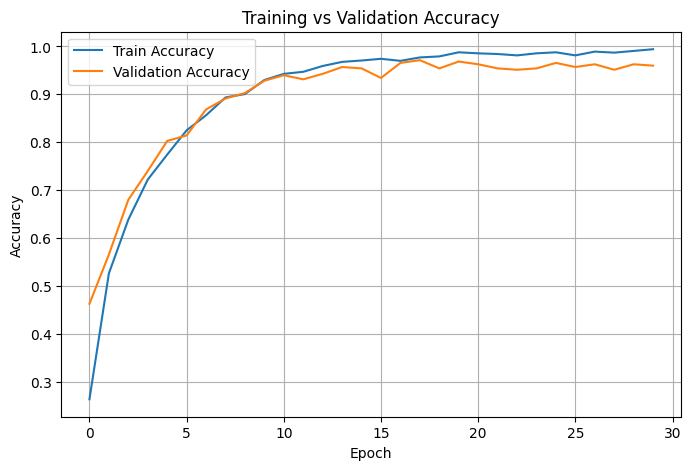

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

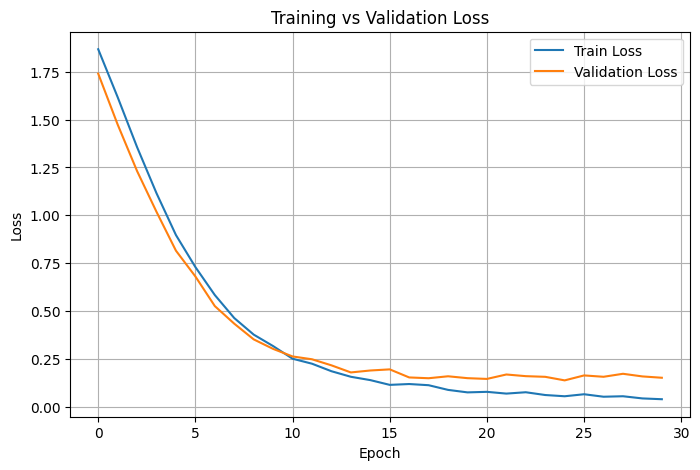

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

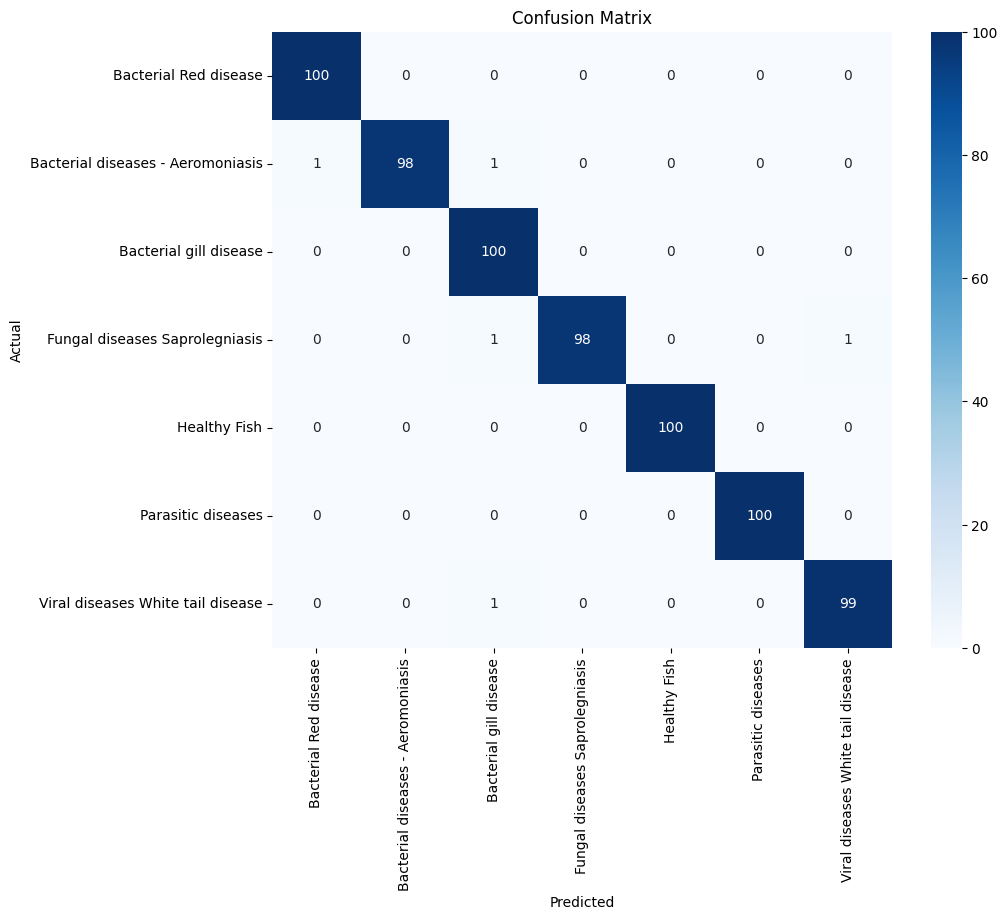

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_test_labels,
    all_test_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [28]:
import numpy as np
import torch

all_labels = []
all_probs = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

print(all_probs.shape)

(700, 7)


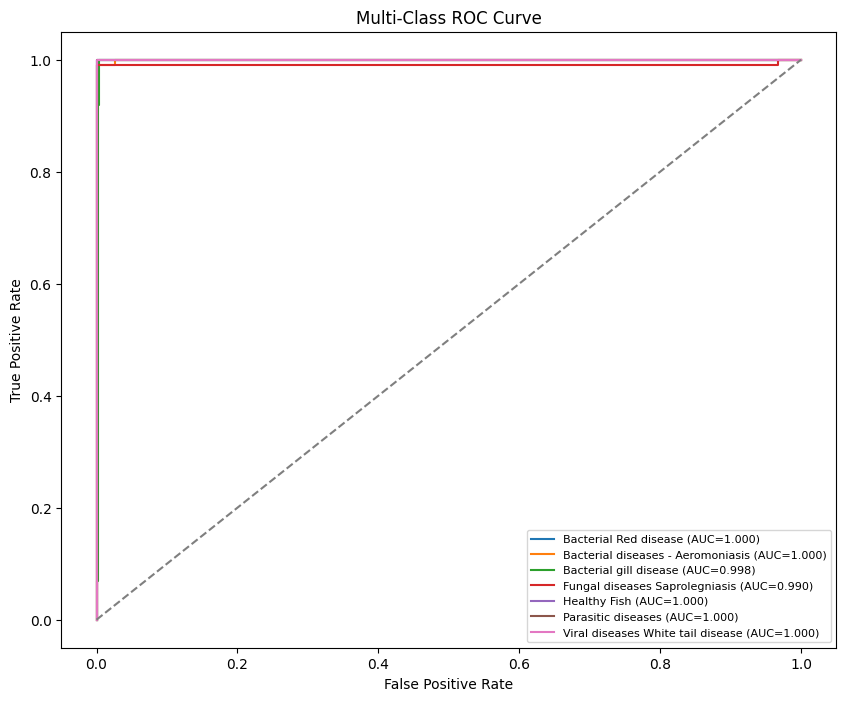

In [29]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

n_classes = len(class_names)

y_true = label_binarize(
    all_labels,
    classes=range(n_classes)
)

plt.figure(figsize=(10,8))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend(loc="lower right", fontsize=8)

plt.show()

In [30]:
from sklearn.metrics import roc_auc_score

auc_score = roc_auc_score(
    y_true,
    all_probs,
    multi_class="ovr"
)

print("Overall ROC-AUC:", round(auc_score,4))

Overall ROC-AUC: 0.9983


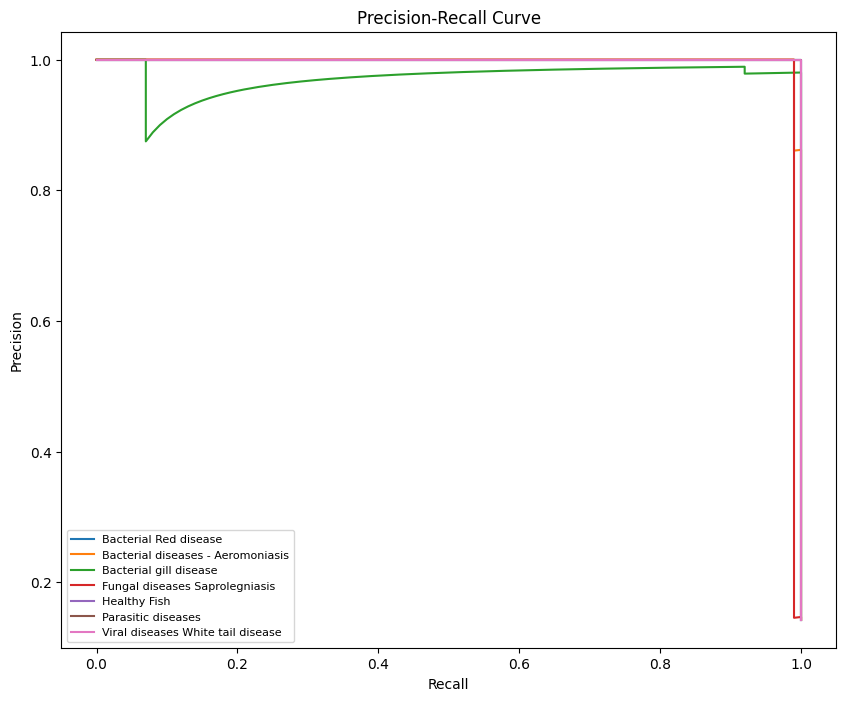

In [31]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

for i in range(n_classes):

    precision, recall, _ = precision_recall_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=class_names[i]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(fontsize=8)

plt.show()

In [32]:
from sklearn.metrics import average_precision_score

ap_score = average_precision_score(
    y_true,
    all_probs,
    average="macro"
)

print("Mean Average Precision:", round(ap_score,4))

Mean Average Precision: 0.9949
